# CWRU dataset — a lab motor bearing

This is the other public sensor set for the benchmark. It is not a wind turbine. A motor was run on a bench at Case Western Reserve University, and accelerometers recorded the vibration. Small pits were cut into real bearings. The waveform was measured, not generated by a computer.

The slice here is enough to see the signal before any training. Four healthy recordings, then inner-race, ball, and outer-race faults at 0.007 inch and 0.021 inch, at no load and at 3 HP. Two extra outer-race files show the pit sitting beside the load or opposite it. The full 12 kHz drive-end set is larger than this slice. Training can use more of it later.

Bearing Data Center, Case Western Reserve University. The files are the official MATLAB downloads.


In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import hilbert

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

from cwru import RECORDS, fault_orders, load_recording
from signals import spectrum

rows = [load_recording(record) for record in RECORDS]
print(f"{len(rows)} recordings")
print(f"fault sample rate {rows[4]['fs']} Hz, healthy sample rate {rows[0]['fs']} Hz")


18 recordings
fault sample rate 12000 Hz, healthy sample rate 48000 Hz


## What one file holds

Each file is one run at one speed. The drive-end accelerometer is the trace this benchmark will use. A fan-end accelerometer is always present. Fault files also have a base accelerometer. The shaft speed is one number for the whole file, not a column that changes through the record.

The fault files are the 12 kHz experiment: about 122,000 samples, which is about 10 seconds. The four healthy files are the normal baseline, sampled at 48 kHz. Files 98, 99, and 100 have about 485,000 samples, again about 10 seconds. File 97 is half of that, about 5 seconds. The file does not name the unit. Healthy values sit near 0.07. A large outer-race fault reaches about 6.7.

Two healthy files, 98 and 99, do not store the speed. The table value from the data center is used there. File 99 also contains a copy of file 98. The loader keeps the arrays that belong to 99.


In [2]:
example = rows[4]
healthy = rows[0]
print(
    f"{example['name']}: drive {example['drive'].size}, "
    f"fan {example['fan'].size}, "
    f"base {None if example['base'] is None else example['base'].size}, "
    f"rpm {example['rpm']:.0f} from the {example['rpm_source']}"
)
print(
    f"{healthy['name']}: drive {healthy['drive'].size}, "
    f"base {'absent' if healthy['base'] is None else healthy['base'].size}, "
    f"{healthy['drive'].size / healthy['fs']:.1f} s at {healthy['fs']} Hz"
)
missing_speed = [row['name'] for row in rows if row['rpm_source'] == 'table']
print("speed taken from the data-center table:", ", ".join(missing_speed))


IR007_0: drive 121265, fan 121265, base 121265, rpm 1797 from the file
Normal_0: drive 243938, base absent, 5.1 s at 48000 Hz
speed taken from the data-center table: Normal_1, Normal_2


## The eighteen recordings

**rms** is the usual size of the trace. **peak** is the hardest sample. **kurt** near 3 is a steady wiggle. A higher kurtosis is a sharp hit. A healthy recording stays near 3. An outer-race pit in the load zone does not.


In [3]:
print(f"{'name':<12} {'fault':<10} {'in':>6} {'HP':>3} {'rpm':>6} {'rate':>6} {'sec':>6} {'rms':>6} {'peak':>6} {'kurt':>6}")
for row in rows:
    x = row["drive"]
    centred = x - x.mean()
    scale = centred.std()
    kurt = float(np.mean((centred / scale) ** 4))
    print(
        f"{row['name']:<12} {row['fault']:<10} {row['diameter_in']:6.3f} {row['load_hp']:3d} "
        f"{row['rpm']:6.0f} {row['fs']:6d} {x.size / row['fs']:6.1f} "
        f"{scale:6.3f} {np.max(np.abs(x)):6.3f} {kurt:6.1f}"
    )


name         fault          in  HP    rpm   rate    sec    rms   peak   kurt
Normal_0     normal      0.000   0   1796  48000    5.1  0.073  0.311    2.8
Normal_1     normal      0.000   1   1772  48000   10.1  0.065  0.346    2.9
Normal_2     normal      0.000   2   1750  48000   10.1  0.063  0.359    2.9
Normal_3     normal      0.000   3   1725  48000   10.1  0.065  0.306    3.0
IR007_0      inner       0.007   0   1797  12000   10.1  0.291  1.739    5.4
IR007_3      inner       0.007   3   1721  12000   10.2  0.314  1.671    5.3
B007_0       ball        0.007   0   1796  12000   10.2  0.139  0.607    3.0
B007_3       ball        0.007   3   1722  12000   10.1  0.154  0.721    2.9
OR007@6_0    outer_6     0.007   0   1796  12000   10.2  0.669  3.630    7.6
OR007@6_3    outer_6     0.007   3   1725  12000   10.2  0.580  3.236    8.0
OR007@3_0    outer_3     0.007   0   1797  12000   10.2  0.769  3.349    4.2
OR007@12_0   outer_12    0.007   0   1797  12000   10.2  0.237  1.763    8.1

## The waveform

The same 0.08 s from four no-load recordings. Healthy is a small steady shake. The inner-race pit repeats a clear hit. The small ball pit is only a little larger than healthy. The outer-race pit, sitting in the load zone, is a much harder hit. A 0.021 inch outer-race pit reaches about 6.7, roughly twenty times the healthy peak.


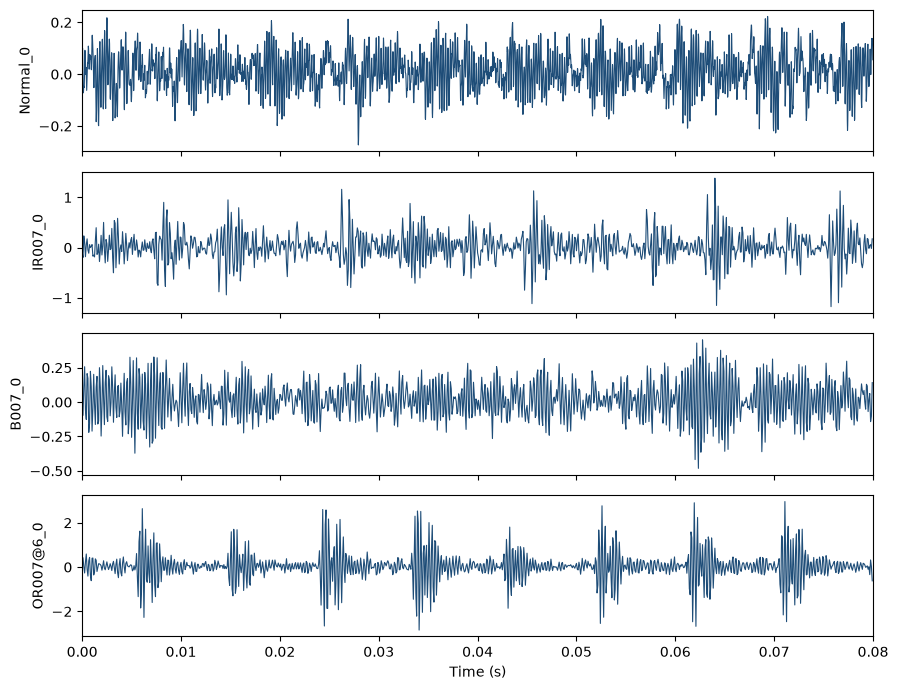

In [4]:
shown = ["Normal_0", "IR007_0", "B007_0", "OR007@6_0"]
fig, axes = plt.subplots(len(shown), 1, figsize=(9, 7), sharex=True)
for ax, name in zip(axes, shown):
    row = next(item for item in rows if item["name"] == name)
    n = int(0.08 * row["fs"])
    t = np.arange(n) / row["fs"]
    ax.plot(t, row["drive"][:n], color="#1e4d78", linewidth=0.8)
    ax.set_ylabel(name)
    ax.set_xlim(0, 0.08)
axes[-1].set_xlabel("Time (s)")
fig.tight_layout()
plt.show()


## Where the hit repeats

The drive-end bearing is an SKF 6205. Nine balls. The inner-race hit is about 5.42 times the shaft speed, and the outer-race hit is about 3.58 times. The plot is the spectrum of the signal envelope over the first two seconds. The marker is that expected rate.

On the inner-race and outer-race files, the loudest line lands on the marker. The small ball fault does not. Its trace also has kurtosis near 3, so a compressor can look accurate on it while missing a fault that is hard to see in the first place.


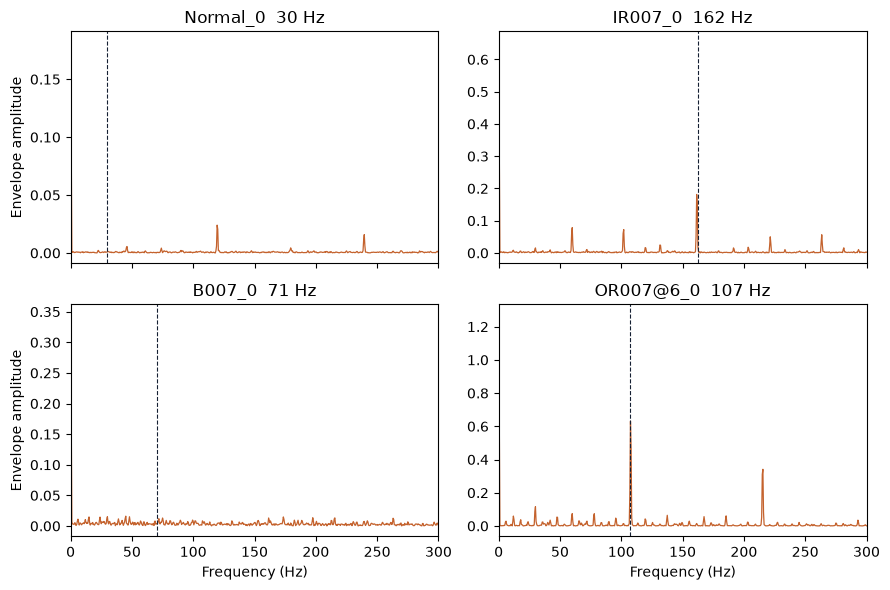

orders: inner 5.42, outer 3.58, ball 2.36


In [5]:
orders = fault_orders()
marked = [
    ("Normal_0", None),
    ("IR007_0", "inner"),
    ("B007_0", "ball"),
    ("OR007@6_0", "outer"),
]
fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True)
for ax, (name, kind) in zip(axes.ravel(), marked):
    row = next(item for item in rows if item["name"] == name)
    n = int(2 * row["fs"])
    x = row["drive"][:n]
    envelope = np.abs(hilbert(x - x.mean()))
    freq, amp = spectrum(envelope, row["fs"])
    band = (freq >= 0) & (freq <= 300)
    ax.plot(freq[band], amp[band], color="#c4622d", linewidth=0.9)
    shaft = row["rpm"] / 60
    target = shaft if kind is None else orders[kind] * shaft
    ax.axvline(target, color="#152033", linewidth=0.8, linestyle="--")
    ax.set_title(f"{name}  {target:.0f} Hz")
    ax.set_xlim(0, 300)
for ax in axes[:, 0]:
    ax.set_ylabel("Envelope amplitude")
for ax in axes[1, :]:
    ax.set_xlabel("Frequency (Hz)")
fig.tight_layout()
plt.show()
print(
    "orders:",
    f"inner {orders['inner']:.2f}, outer {orders['outer']:.2f}, ball {orders['ball']:.2f}",
)


## What changes for the compressor

The turbine recording carries a gear tone near shaft order 35, and the speed changes from visit to visit. This motor does not. The speed is one number near 1,720–1,800 RPM, and the repeating event is the bearing pit, a few times per revolution.

A later split has to keep each file whole. Cutting one file into blocks and putting some blocks in training would leak the same run into the test. Healthy and fault files also cannot be mixed until the healthy traces are resampled from 48 kHz to 12 kHz.

The next experiment is the same comparison as on the turbine: file size, how much of the recording comes back, and the time to encode and decode, against Rice and zlib. The order-35 tone belongs to the turbine gearbox, so it is not copied onto this motor.
